# Testing inference: multiple patterns in a long sequence

The trained readout from notebook 11 is loaded from the cache and probed **in retrieval
mode**: all 16 motifs are concatenated into one long input stream, each flanked by
`N_iti_time = 4*N_pretime = 200` ms of silence (no spontaneous activity), and only its first `num_delay` ms is injected as a trigger. The network -
with no further plasticity - must then re-emit each motif from the correct onset onward.
This is a *chain-retrieval* stress test of the fixed weights (no retraining).

## Notebook summary

### Pipeline
1. Load `<datetag>_vanilla.pth` via `mnesis_chains.load()` (StochasticSpikingPattern).
2. Concatenate the 16 motifs (with long ITI pads) into a single `(N_neuron, T)` stream;
    build the per-motif trigger masks; run one single `forward_pass` on the stream.
3. Score every consecutive `window_size=60` ms window with `get_f1score(spikes_window, target_window)`
    against the frozen motifs,
    cached as `<datetag>_score.npy` under the standard `.lock` protocol.
4. Plot the F1 trajectory and an animated version (`retrieval.pdf` / `retrieval.mp4`).

### Main outputs
- cache `../cached_data/<datetag>_score.npy` (+ `.lock`);
- figures `retrieval.pdf/png/svg` and (when figpath is active) the `retrieval.mp4` animation.


In [1]:
# load() rebuilds the HD_SNN architecture, restores <datetag>_vanilla.pth and
# attaches a default StochasticSpikingPattern (see mnesis_chains.load()).
from mnesis_boilerplate import torch, np, plt, data_cache, figpath, RECOMPUTE, Params
from mnesis_boilerplate import printfig, get_f1score
from mnesis_chains import load
# RECOMPUTE = True

datetag = '2026-09-07'
Using device: mps


In [2]:
opt = Params()
model_filename = data_cache / f"{opt.datetag}_vanilla.pth"
hd = load(opt, model_filename)
print(f"Model weights loaded from {model_filename} - the pattern generator is the {hd.pattern_object.desc}")

Model weights loaded from ../cached_data/2026-09-07_vanilla.pth - the pattern generator is the Stochastic spike pattern generator


## Retrieval across a long, concatenated sequence with all motifs

Construction of the input stream: `concat_motifs` pads every motif with
`N_iti_time = 4*N_pretime = 200` ms of silence on both sides and concatenates the 16 motifs
head-to-tail, giving `(N_neuron, N_pattern * (N_time + 2*N_iti_time))` tensors:

- `target_full`: the frozen motifs - the *reference* to score against;
- `cue_full`: a seeded noisy realisation (`pattern_object(seed=seed)`);
- `evoked`: 1 over each motif's full duration - the ideal retrieval envelope;
- `mask`: 1 on each motif's first `num_delay` bins, 0 elsewhere - keeps only the trigger;
- `input_spikes = cue_full * mask`: the concatenated triggers (spontaneous activity is
   silenced here, unlike `get_input_spikes`, to isolate pure trigger-driven retrieval).

Scanning: `get_f1score` is evaluated in consecutive `window_size=60` ms windows starting at
`onsets`, giving the per-position retrieval quality along the stream.

In [3]:
# One-shot scan: cached F1 scores per 60-ms window along the concatenated stream.
window_size = 60
N_iti_time = opt.N_pretime * 4
T_full = opt.N_pattern * (opt.N_time + 2*N_iti_time)

def concat_motifs(x):
    """Pad each motif of x (N_pattern, N_neuron, N_time) with N_iti_time silent bins
    on both sides and concatenate them in time -> (N_neuron, T_full)."""
    x = torch.nn.functional.pad(x, (N_iti_time, N_iti_time))
    return x.permute((1, 0, 2)).reshape((opt.N_neuron, T_full))

# the frozen motifs are the reference; a seeded noisy realisation provides the triggers
target_full = concat_motifs(hd.pattern_object.frozen_target)
cue_full = concat_motifs(hd.pattern_object(seed=opt.seed))
ones = torch.ones_like(hd.pattern_object.frozen_target)
evoked = concat_motifs(ones)
mask = ones.clone()
mask[:, :, opt.num_delay:] = 0
mask = concat_motifs(mask)

onsets = np.arange(0, T_full - window_size + 1, window_size)

npy_filename = data_cache / f"{hd.opt.datetag}_score.npy"
lock_filename = npy_filename.with_suffix('.lock')
# RECOMPUTE = True # the cache key ignores window_size: comment out only to reuse a score computed with the same window
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True)
    lock_filename.unlink(missing_ok=True)
scores_np = None
try:
    scores_np = np.load(npy_filename)
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Scores loaded from {npy_filename}")
except FileNotFoundError:
    if lock_filename.exists():
        print(f"Score file is locked: {lock_filename}, passing.")
    else:
        print(f"Score file not found: {npy_filename}, evaluating the score.")
        lock_filename.touch()
        with torch.no_grad():
            _, _, spikes = hd.forward_pass((cue_full * mask).unsqueeze(0).to(opt.device))
        spikes = spikes.squeeze(0)
        scores_np = np.array([get_f1score(spikes[:, t:t+window_size], target_full[:, t:t+window_size]).item()
                              for t in onsets])
        np.save(npy_filename, scores_np)
        lock_filename.unlink(missing_ok=True)

# reference curves, sampled at the onset of each scoring window
evoked_np = evoked.mean(dim=0).cpu().numpy()[onsets]
mask_np = mask.mean(dim=0).cpu().numpy()[onsets]

Score file not found: ../cached_data/2026-09-07_score.npy, evaluating the score.


## F1 trajectory of the retrieval scan

Curves vs the onset time (ms): `evoked_np` (ideal 1 while a motif should be re-emitted -
the reference envelope), `mask_np` (1 only on each trigger's `num_delay`-ms window) and
`scores_np` (the measured per-window F1). Retrieval should light up after every trigger.

Saving as ../figures/retrieval.pdf
Saving as ../figures/retrieval.png
Saving as ../figures/retrieval.svg


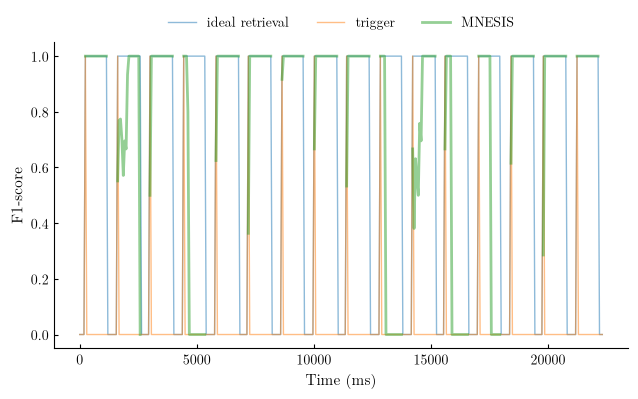

In [4]:
def plot_retrieval(ax):
    # colours follow the default cycle (C0, C1, C2), as described in the caption of fig:retrieval
    ax.plot(onsets, evoked_np, alpha=.5, label='ideal retrieval')
    ax.plot(onsets, mask_np, alpha=.5, label='trigger')
    # F1 shown on the motifs only: in the ITIs the target is empty, so F1 is 0 whatever the network does
    ax.plot(onsets, np.where(evoked_np > 0, scores_np, np.nan), lw=2, alpha=.5, label='MNESIS')
    # motif number (1-based, as the ordinals of the caption of fig:retrieval) above the centre of each motif;
    # clip_on keeps the labels outside the viewport of the animation hidden
    for k in range(opt.N_pattern):
        ax.text(k*(opt.N_time + 2*N_iti_time) + N_iti_time + opt.N_time/2, 1.03, f'{k+1}',
                ha='center', va='bottom', fontsize='small', clip_on=True)
    # headroom for the labels, with the ticks kept on the [0, 1] range of the F1-score
    ax.set_ylim(-.05, 1.15)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("F1-score")
    # the curves span the whole [0, 1] range: the legend goes above the axes
    ax.legend(loc='lower center', bbox_to_anchor=(.5, 1.), ncols=3, frameon=False)

if scores_np is not None:
    fig, ax = plt.subplots()
    plot_retrieval(ax)
    printfig(fig, 'retrieval', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)

### Animated version

Same figure seen through a viewport of `n_view=100` scoring windows (6 s) swept along the
stream by steps of 5 windows (`ffmpeg`, 10 fps -> `retrieval.mp4`); same colours as the
static figure.

In [ ]:
if scores_np is not None and figpath is not None:
    filename = figpath / 'retrieval.mp4'
    RECOMPUTE = True # comment out to reuse a previously computed video
    if not filename.exists() or RECOMPUTE:
        import matplotlib.animation as animation
        cm = 1/2.54  # centimetres in inches (matplotlib figsize)
        n_view, step = 100, 5  # viewport width and shift between frames (scoring windows)

        # the curves are drawn once; each frame only moves the x limits
        fig, ax = plt.subplots(figsize=(opt.fig_width*cm, opt.fig_height*cm))
        plot_retrieval(ax)

        def animate(frame):
            ax.set_xlim(onsets[frame], onsets[frame + n_view - 1])
            return []

        anim = animation.FuncAnimation(fig, animate, frames=range(0, len(onsets) - n_view + 1, step))
        anim.save(filename, writer='ffmpeg', fps=10)
        plt.close(fig)